ˆ
𝛉 = (X⊺X)−1X⊺y

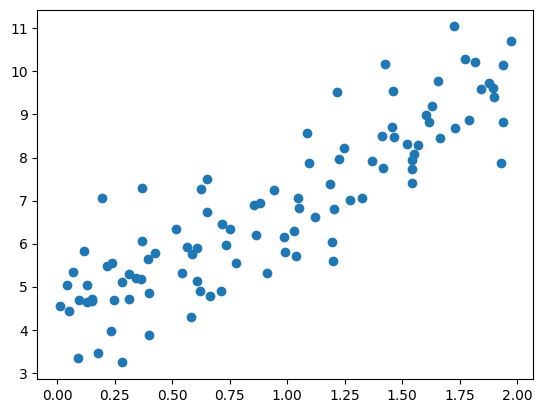

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
m=100
X = 2 * np.random.rand(m,1)
Y= 4+3*X + np.random.randn(m,1)
plt.scatter(X,Y)
plt.show()

In [2]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y
print(theta_best)

[[4.21509616]
 [2.77011339]]


here the real value is 4 and 3 it close enough but the gaussian noise made it impossible to know the exact value

In [3]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new)
y_predict = X_new_b @ theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

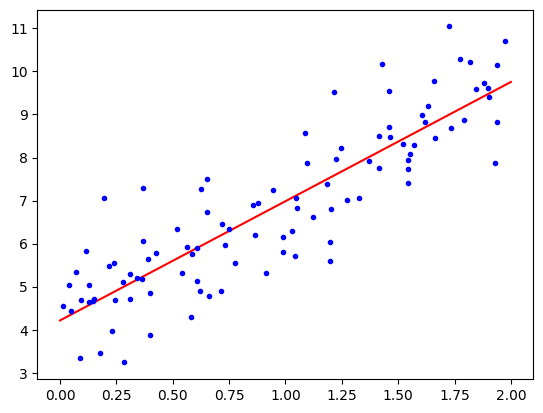

In [4]:

plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, Y, "b.")
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X,Y)
lin_reg.intercept_,lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

In [6]:
lin_reg.predict(X_new)

array([[4.21509616],
       [9.75532293]])

coef does not include the bias

In [7]:
np.linalg.pinv(X_b) @ Y

array([[4.21509616],
       [2.77011339]])

the pseudoinverse use SVD that handle the expection very good ,the method normal need X.t @ X to be invertible

and also in complexity svd is about O(n**2) but the normal method need to inverse the matrix that is go between O(n**2,4) and O(n**3)

In [8]:
eta = 0.1
n_epochs = 1000
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2,1)
for epoch in range(n_epochs):
    gradients = 2/m * X_b.T @ (X_b @ theta-Y)
    theta-=eta * gradients

theta

array([[4.21509616],
       [2.77011339]])

In [9]:
n_epochs = 50
t0,t1 = 5,50

def learning_schedule(t):
    return t0/(t+t1)

np.random.seed(42)
theta = np.random.randn(2,1)

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = Y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta-yi)
        eta = learning_schedule(m*epoch + iteration)
        theta -= eta * gradients
theta


array([[4.21076011],
       [2.74856079]])

In [10]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(tol=1e-5,eta0=0.01,penalty=None,max_iter=1000,n_iter_no_change=100)
sgd_reg.fit(X_b,Y.ravel())

sgd_reg.intercept_ , sgd_reg.coef_

(array([2.10740242]), array([2.10740242, 2.77002913]))

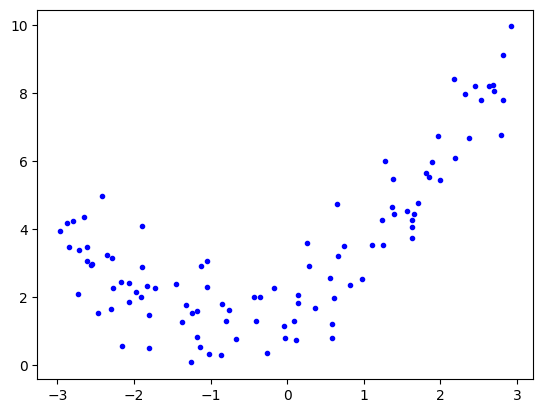

In [ ]:
np.random.seed(42)
m=100
X = 6*np.random.rand(m,1) -3
Y = 0.5* X**(2) + X + 2 + np.random.randn(m,1)
plt.plot(X,Y,"b.")
plt.show()

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree=2,include_bias=False)
X_poly = poly_features.fit_transform(X)
X[0]

array([-0.75275929])

In [ ]:
X_poly[0]

array([-0.75275929,  0.56664654])

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly,Y)
lin_reg.intercept_,lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

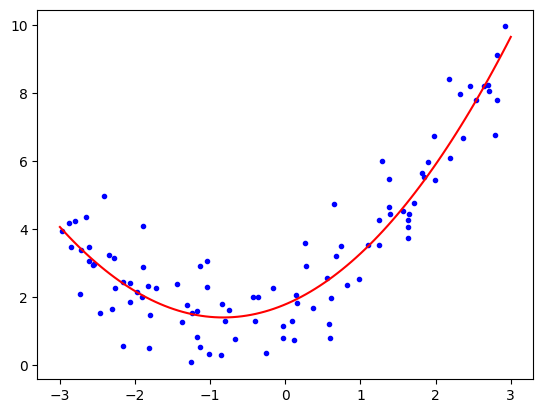

In [15]:
X_new = np.linspace(-3,3,100).reshape(100,1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.plot(X,Y,"b.")
plt.plot(X_new,y_new,"r-")
plt.show()

Learning Curves

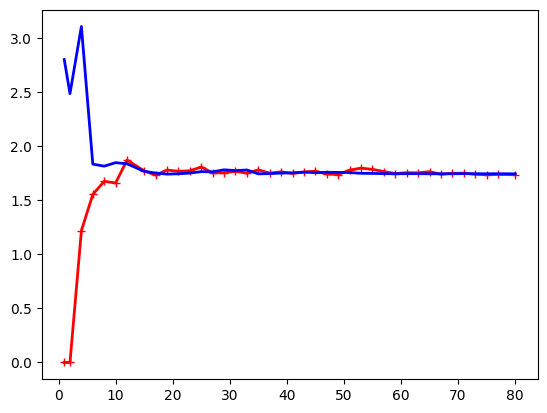

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes , train_scores ,valid_scores = learning_curve(LinearRegression(),X,Y,
                                        train_sizes = np.linspace(0.01,1.0,40),cv=5,scoring="neg_root_mean_squared_error")

train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)
plt.plot(train_sizes,train_errors,"r-+",linewidth=2)
plt.plot(train_sizes,valid_errors,"b-",linewidth=2)
plt.show()

its clear that is an underfitting because the model fit the data when we have a small set but when we scale the model become harder to fit becaude the data is noisy and the data is not linear, and we have also that the curves meet and goes in two lines

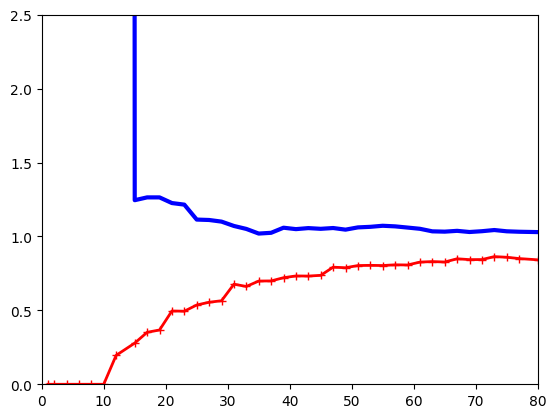

In [ ]:
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline(PolynomialFeatures(degree=10,include_bias=False),
                                      LinearRegression())

train_sizes , train_scores , valid_scores = learning_curve(polynomial_regression,X,Y,train_sizes=np.linspace(0.01,1.0,40),
                                                           cv=5,scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.plot(train_sizes,train_errors,"r-+",linewidth=2)
plt.plot(train_sizes,valid_errors,"b-",linewidth=3)
plt.axis([0, 80, 0, 2.5])
plt.show()

we can see the curve of train is much lower but the gap is bigger than before and that may overfit

the bias/variance trade-off 

the generalization error expressed as the sum of bias , variance and irreductible error
bias is due to wrong assumption if its big we can say that the model overfit
variance model sensitivity to small variance , if its bigger then the model overfit
irreductible noise due to noise of ur data

Regularized models

this using closed form solution and the cholesky decomposer

In [ ]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha=0.1,solver="cholesky") #in sklearn +alpha/m * norm2
ridge_reg.fit(X,Y)
ridge_reg.predict([[1.5]])

array([4.82899748])

In [ ]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(penalty="l2",alpha=0.1/m,tol=None,max_iter=1000,eta0=0.01,random_state=42)
sgd_reg.fit(X,Y.ravel())
sgd_reg.predict([[1.5]])

array([4.82830117])

the most important characterictic of lasso is the sparsity is selecting the most import important features and dropping out the least important

and for ridge the gradient slow down naturally and that help ridge go faster to the mini

In [ ]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.1) #in sklearn +2*alpha*norm1
lasso.fit(X,Y)
lasso.predict([[1.5]])

array([4.77621741])

and for sgdregressor use the same but choose l1 for penalty

elastic net regression + r(2*alpha*norm1)+(1-r)alpha/m*norm2
it combines the sparsity and the smoothest of ridge

In [ ]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1,l1_ratio=0.5)
elastic_net.fit(X,Y)
elastic_net.predict([[1.5]])

array([4.78114505])

In [22]:
from copy import deepcopy
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

preprocessing = make_pipeline(PolynomialFeatures(degree=90, include_bias=False),
                              StandardScaler())
X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty=None, eta0=0.002, random_state=42)
n_epochs = 500
best_valid_rmse = float('inf')
train_errors, val_errors = [], []

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = root_mean_squared_error(y_valid, y_valid_predict)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)  # we have that base.clone only store hyperparameters and deepcopy store also teta

    
    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = root_mean_squared_error(y_train, y_train_predict)
    val_errors.append(val_error)
    train_errors.append(train_error)

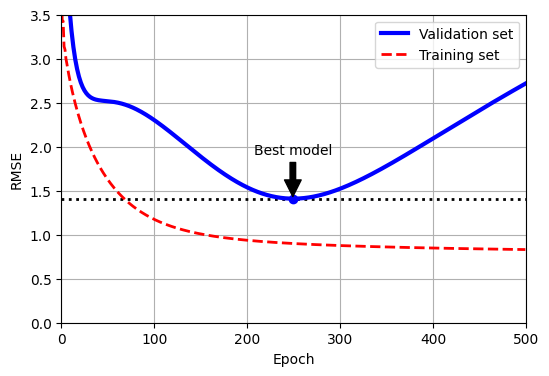

In [ ]:

best_epoch = np.argmin(val_errors)
plt.figure(figsize=(6, 4))
plt.annotate('Best model',
             xy=(best_epoch, best_valid_rmse),
             xytext=(best_epoch, best_valid_rmse + 0.5),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.plot([0, n_epochs], [best_valid_rmse, best_valid_rmse], "k:", linewidth=2)
plt.plot(val_errors, "b-", linewidth=3, label="Validation set")
plt.plot(best_epoch, best_valid_rmse, "bo")
plt.plot(train_errors, "r--", linewidth=2, label="Training set")
plt.legend(loc="upper right")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()

Logistic Regression

a regression used for classification
p = sigma(teta.T @ x)
sigma(t)=1/1+exp(-t)
its binary classification

if p>=0.5 its one else its zero

logit(p) = log(p / (1 – p))

logloss = ylog(p) +(1-y)log(1-p) 

we can prove that by the log likelihood using logistic regression and normal distribution

the bad news that there no close form to solve the gradient of this equation and the good news is tjat the gradient is convex

Decision Boundaries

In [24]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [25]:
iris.data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [26]:
iris.target.head()

,target
0,0
1,0
2,0
3,0
4,0


In [27]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'

X_train ,X_test ,y_train,y_test  = train_test_split(X,y,random_state=42)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train,y_train)

LogisticRegression(random_state=42)

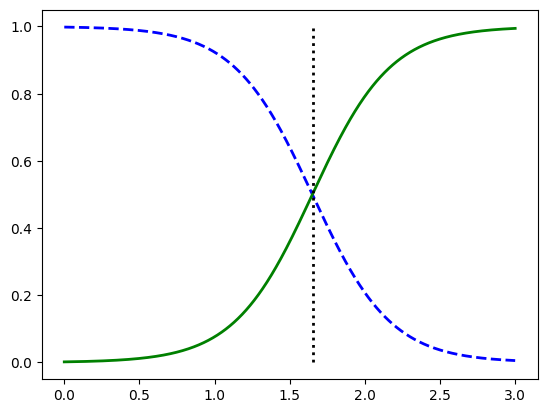

In [32]:
X_new = np.linspace(0,3,1000).reshape(-1,1)
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:,1]>=0.5][0,0]

plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2,
label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2,
label="Decision boundary")
plt.show()

In [33]:
decision_boundary

np.float64(1.6516516516516517)

In [35]:
log_reg.predict([[1.6],[1.7]])

array([False,  True])

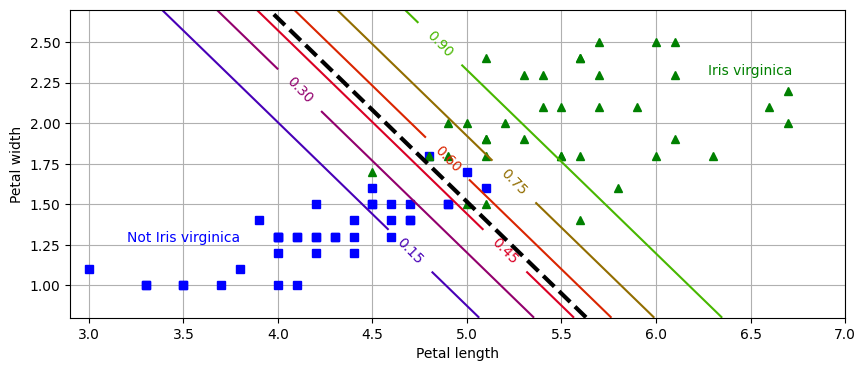

In [48]:
# extra code – this cell generates and saves Figure 4–24

X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

log_reg = LogisticRegression(C=2, random_state=42)
log_reg.fit(X_train, y_train)

# for the contour plot
x0, x1 = np.meshgrid(np.linspace(2.9, 7, 500).reshape(-1, 1),
                     np.linspace(0.8, 2.7, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]  # one instance per point on the figure
y_proba = log_reg.predict_proba(X_new)
zz = y_proba[:, 1].reshape(x0.shape)

# for the decision boundary
left_right = np.array([2.9, 7])
boundary = -((log_reg.coef_[0, 0] * left_right + log_reg.intercept_[0])
             / log_reg.coef_[0, 1])

plt.figure(figsize=(10, 4))
plt.plot(X_train[y_train == 0, 0], X_train[y_train == 0, 1], "bs")
plt.plot(X_train[y_train == 1, 0], X_train[y_train == 1, 1], "g^")
contour = plt.contour(x0, x1, zz, cmap=plt.cm.brg)
plt.clabel(contour, inline=1)
plt.plot(left_right, boundary, "k--", linewidth=3)
plt.text(3.5, 1.27, "Not Iris virginica", color="b", ha="center")
plt.text(6.5, 2.3, "Iris virginica", color="g", ha="center")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.axis([2.9, 7, 0.8, 2.7])
plt.grid()
plt.show()

Softmax Regression 

can be generalizad to multiple classes

cross entropy cost function
sum(sum(-ylog(p)))

CROSS ENTROPY
Cross entropy originated from Claude Shannon’s information theory. Suppose
you want to efficiently transmit information about the weather every day. If
there are eight options (sunny, rainy, etc.), you could encode each option using 3
bits, because 2**3 = 8. However, if you think it will be sunny almost every day, it
would be much more efficient to code “sunny” on just one bit (0) and the other
seven options on four bits (starting with a 1). Cross entropy measures the
average number of bits you actually send per option. If your assumption about
the weather is perfect, cross entropy will be equal to the entropy of the weather
itself (i.e., its intrinsic unpredictability). But if your assumption is wrong (e.g.,
if it rains often), cross entropy will be greater by an amount called the
Kullback–Leibler (KL) divergence.
The cross entropy between two probability distributions p and q is defined as
H(p,q) = –Σx p(x) log q(x) (at least when the distributions are discrete). For
more details, check out my video on the subject.

In [38]:
iris.data.head

<bound method NDFrame.head of      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  5.1               3.5                1.4               0.2
1                  4.9               3.0                1.4               0.2
2                  4.7               3.2                1.3               0.2
3                  4.6               3.1                1.5               0.2
4                  5.0               3.6                1.4               0.2
..                 ...               ...                ...               ...
145                6.7               3.0                5.2               2.3
146                6.3               2.5                5.0               1.9
147                6.5               3.0                5.2               2.0
148                6.2               3.4                5.4               2.3
149                5.9               3.0                5.1               1.8

[150 rows x 4 columns]>

In [39]:
X = iris.data[["petal length (cm)","petal width (cm)"]]
y=iris["target"]

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42)

In [41]:
softmax_reg = LogisticRegression(C=30,random_state=42)
softmax_reg.fit(X_train,y_train)

LogisticRegression(C=30, random_state=42)

In [43]:
softmax_reg.predict([[5,2]])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([2])

In [44]:
softmax_reg.predict_proba([[5,2]]).round(2)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[0.  , 0.04, 0.96]])

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


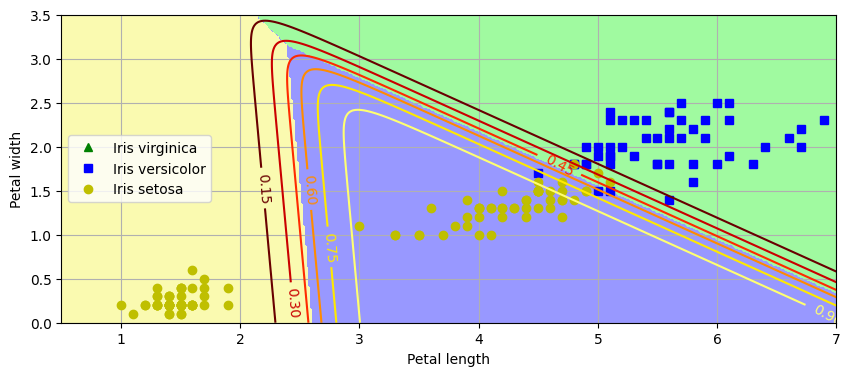

In [49]:
# extra code – this cell generates and saves Figure 4–25
from matplotlib.colors import ListedColormap

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

x0, x1 = np.meshgrid(np.linspace(0, 8, 500).reshape(-1, 1),
                     np.linspace(0, 3.5, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

y_proba = softmax_reg.predict_proba(X_new)
y_predict = softmax_reg.predict(X_new)

zz1 = y_proba[:, 1].reshape(x0.shape)
zz = y_predict.reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")

plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap="hot")
plt.clabel(contour, inline=1)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="center left")
plt.axis([0.5, 7, 0, 3.5])
plt.grid()
plt.show()